In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import nltk
import re

In [ ]:
df = pd.read_csv("twitter_validation.csv")
df

,3364,Facebook,Irrelevant,"I mentioned on Facebook that I was struggling for motivation to go for a run the other day, which has been translated by Tom’s great auntie as ‘Hayley can’t get out of bed’ and told to his grandma, who now thinks I’m a lazy, terrible person 🤣"
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...
...,...,...,...,...
994,4891,GrandTheftAuto(GTA),Irrelevant,⭐️ Toronto is the arts and culture capital of ...
995,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
996,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
997,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.columns=['id','media','target','text']

In [ ]:
df.shape

(999, 4)

In [ ]:
df.head()

,id,media,target,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...


In [ ]:
df.tail()

,id,media,target,text
994,4891,GrandTheftAuto(GTA),Irrelevant,⭐️ Toronto is the arts and culture capital of ...
995,4359,CS-GO,Irrelevant,tHIS IS ACTUALLY A GOOD MOVE TOT BRING MORE VI...
996,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
997,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.
998,6960,johnson&johnson,Neutral,Johnson & Johnson to stop selling talc baby po...


In [ ]:
df.isna().sum()

,0
id,0
media,0
target,0
text,0


In [ ]:
target = df["target"].value_counts()


<BarContainer object of 4 artists>

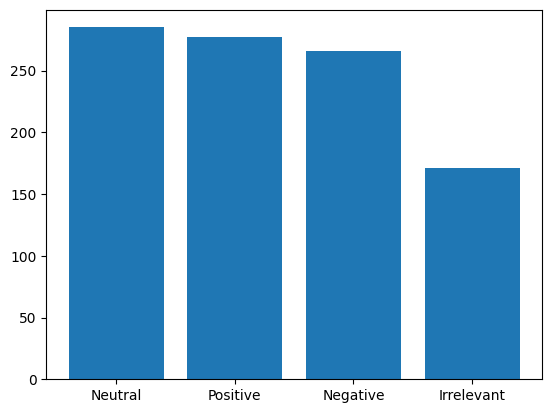

In [ ]:
plt.bar(target.index,target.values)

In [ ]:
df.drop(df.index[(df['target'] == 'Irrelevant')],axis=0, inplace=True)

In [ ]:
df

,id,media,target,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...
...,...,...,...,...
992,314,Amazon,Negative,Please explain how this is possible! How can t...
993,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
996,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
997,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.reset_index(drop=True,inplace=True)
df

,id,media,target,text
0,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
1,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
2,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
3,4433,Google,Neutral,Now the President is slapping Americans in the...
4,6273,FIFA,Negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...
...,...,...,...,...
823,314,Amazon,Negative,Please explain how this is possible! How can t...
824,9701,PlayStation5(PS5),Positive,Good on Sony. As much as I want to see the new...
825,2652,Borderlands,Positive,Today sucked so it’s time to drink wine n play...
826,8069,Microsoft,Positive,Bought a fraction of Microsoft today. Small wins.


In [ ]:
df.drop(['id','media'],axis=1,inplace=True)

In [ ]:
df['target'] = df['target'].map({
    'Positive': 1,
    'Negative': -1,
    'Neutral': 0
})
df

,target,text
0,0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,-1,@Microsoft Why do I pay for WORD when it funct...
2,-1,"CSGO matchmaking is so full of closet hacking,..."
3,0,Now the President is slapping Americans in the...
4,-1,Hi @EAHelp I’ve had Madeleine McCann in my cel...
...,...,...
823,-1,Please explain how this is possible! How can t...
824,1,Good on Sony. As much as I want to see the new...
825,1,Today sucked so it’s time to drink wine n play...
826,1,Bought a fraction of Microsoft today. Small wins.


In [ ]:
tweet = df.text
nltk.download('stopwords')
nltk.download('punkt_tab')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
# tokenization
from nltk.tokenize import TweetTokenizer
tk = TweetTokenizer()
tweet = tweet.apply(lambda x: ' '.join(tk.tokenize(x)))
tweet

,text
0,BBC News - Amazon boss Jeff Bezos rejects clai...
1,@Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi @EAHelp I ’ ve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible ! How can ...
824,Good on Sony . As much as I want to see the ne...
825,Today sucked so it ’ s time to drink wine n pl...
826,Bought a fraction of Microsoft today . Small w...


In [ ]:
# remove special characters
tweet = tweet.str.replace('[^a-zA-Z0-9]',' ',regex=True)
tweet

,text
0,BBC News Amazon boss Jeff Bezos rejects clai...
1,Microsoft Why do I pay for WORD when it funct...
2,CSGO matchmaking is so full of closet hacking ...
3,Now the President is slapping Americans in the...
4,Hi EAHelp I ve had Madeleine McCann in my c...
...,...
823,Please explain how this is possible How can ...
824,Good on Sony As much as I want to see the ne...
825,Today sucked so it s time to drink wine n pl...
826,Bought a fraction of Microsoft today Small w...


In [ ]:
#minimum characters 3
tweet = tweet.apply(lambda x: " ".join([w for w in tk.tokenize(x) if len(w) >= 3]))
tweet

,text
0,BBC News Amazon boss Jeff Bezos rejects claims...
1,Microsoft Why pay for WORD when functions poor...
2,CSGO matchmaking full closet hacking truly awf...
3,Now the President slapping Americans the face ...
4,EAHelp had Madeleine McCann cellar for the pas...
...,...
823,Please explain how this possible How can they ...
824,Good Sony much want see the new PS5 what going...
825,Today sucked time drink wine play borderlands ...
826,Bought fraction Microsoft today Small wins


In [ ]:
# stemming
from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')

# Just join the list of stemmed words (x) directly
tweet = tweet.apply(lambda x: [st.stem(i.lower()) for i in tk.tokenize(x)]).apply(lambda x: ' '.join(x))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay for word when function poor ...
2,csgo matchmak full closet hack truli aw game
3,now the presid slap american the face that rea...
4,eahelp had madelein mccann cellar for the past...
...,...
823,pleas explain how this possibl how can they le...
824,good soni much want see the new ps5 what go ri...
825,today suck time drink wine play borderland unt...
826,bought fraction microsoft today small win


In [ ]:
from nltk.corpus import stopwords
stop = stopwords.words('english')
tweet = tweet.apply(lambda x: [i for i in tk.tokenize(x) if i not in stop]).apply(lambda x : ' '.join(x))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay word function poor samsungus...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,pleas explain possibl let compani overcharg sc...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


In [ ]:
# stemming
from nltk.stem import SnowballStemmer
st = SnowballStemmer('english')
tweet = tweet.apply(lambda x: ' '.join([st.stem(i.lower()) for i in tk.tokenize(x)]))
tweet

,text
0,bbc news amazon boss jeff bezo reject claim co...
1,microsoft whi pay word function poor samsungus...
2,csgo matchmak full closet hack truli aw game
3,presid slap american face realli commit unlaw ...
4,eahelp madelein mccann cellar past year littl ...
...,...
823,plea explain possibl let compani overcharg sca...
824,good soni much want see new ps5 go right much ...
825,today suck time drink wine play borderland sun...
826,bought fraction microsoft today small win


In [ ]:
# vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
vec = TfidfVectorizer()
data = vec.fit_transform(tweet)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10459 stored elements and shape (828, 3759)>

In [ ]:
print(data)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10459 stored elements and shape (828, 3759)>
  Coords	Values
  (0, 515)	0.49155204783978756
  (0, 2264)	0.38864111655856126
  (0, 353)	0.1515362387424402
  (0, 610)	0.22681557001542715
  (0, 1811)	0.24577602391989378
  (0, 545)	0.2608257828483461
  (0, 2737)	0.2608257828483461
  (0, 785)	0.21432663830218204
  (0, 838)	0.17354914655342313
  (0, 286)	0.22681557001542715
  (0, 1974)	0.13277165480466424
  (0, 1107)	0.23509805002803952
  (0, 981)	0.2608257828483461
  (0, 668)	0.2608257828483461
  (1, 2132)	0.24555654927912696
  (1, 3615)	0.26216072802580975
  (1, 2438)	0.3126902562590763
  (1, 3656)	0.36557591217188057
  (1, 1382)	0.4055823664694651
  (1, 2534)	0.3821800909185634
  (1, 2867)	0.4055823664694651
  (1, 775)	0.4055823664694651
  (2, 933)	0.3041178383627944
  (2, 2083)	0.3963165794888645
  (2, 1379)	0.3790982275064499
  :	:
  (825, 3359)	0.2560582225152133
  (825, 3369)	0.3395996844494918
  (825, 826)	0.25069214907989

In [ ]:
y = df['target']
x = data


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier(n_neighbors=7)
model.fit(x_train,y_train)
y_pred1 = model.predict(x_test)
from sklearn.metrics import accuracy_score
score1 = (accuracy_score(y_test,y_pred1))
score1

0.4879518072289157

In [ ]:
from sklearn.naive_bayes import MultinomialNB
model3 = MultinomialNB()
model3.fit(x_train,y_train)
y_pred2 = model3.predict(x_test)
score2 =(accuracy_score(y_test,y_pred2))
score2

0.5421686746987951

In [ ]:
from sklearn.tree import DecisionTreeClassifier
model1 = DecisionTreeClassifier()
model1.fit(x_train,y_train)
y_pred3 = model1.predict(x_test)
from sklearn.metrics import accuracy_score
score3 = (accuracy_score(y_test,y_pred3))
score3

0.5180722891566265

In [ ]:
from sklearn.ensemble import RandomForestClassifier
model2 = RandomForestClassifier()
model2.fit(x_train,y_train)
y_pred4 = model2.predict(x_test)
score4 = (accuracy_score(y_test,y_pred4))
score4

0.536144578313253

In [ ]:
df2 = pd.DataFrame({"model":[model,model1,model2,model3],"score":[score1,score2,score3,score4]})
df2

,model,score
0,KNeighborsClassifier(n_neighbors=7),0.487952
1,DecisionTreeClassifier(),0.542169
2,"(DecisionTreeClassifier(max_features='sqrt', r...",0.518072
3,MultinomialNB(),0.536145


In [ ]:
review = ['the movie is good']
data1 = vec.transform(review)
y_pred7 = model3.predict(data)
y_pred7


array([ 0, -1,  0,  0, -1,  1,  1, -1, -1,  1,  1, -1,  0, -1,  1,  1, -1,
        1, -1, -1,  0,  1,  0,  0, -1, -1,  1,  1, -1, -1, -1,  1,  0,  1,
        0,  1,  0,  0,  0,  1,  0, -1, -1, -1,  0,  1, -1, -1,  1,  0,  1,
        1, -1, -1, -1,  1,  1, -1,  0, -1,  0, -1,  1,  0, -1,  1,  1, -1,
        0,  0,  0,  1,  1,  0,  1,  0,  1,  1,  1,  0, -1,  1, -1, -1,  0,
        0, -1,  0, -1,  1,  1,  0,  1,  0,  1, -1,  0,  1,  0, -1,  0, -1,
        0,  0,  1,  1,  0, -1, -1,  1,  0,  1, -1,  1,  0, -1,  0,  1,  1,
        1,  1,  0,  0,  0,  0,  1,  0,  1,  1, -1,  0,  0,  1,  0, -1,  0,
        1,  1,  0, -1,  0, -1, -1, -1,  1,  1,  1,  0,  0, -1,  0,  0,  0,
        1,  0, -1, -1,  0,  1,  1,  0,  1,  1,  0,  0, -1, -1, -1, -1,  1,
        0,  0,  1,  1,  0,  1,  1,  1,  1,  0, -1, -1,  0,  1,  1, -1, -1,
        1,  1, -1,  0,  1, -1,  1,  0, -1,  0,  0,  1,  1,  1,  1,  0,  1,
        0, -1,  1,  1,  0,  1,  0,  0, -1, -1,  0,  1,  0, -1,  0,  0, -1,
        1,  1, -1,  0,  1